# Results notebook — CIFAR-10 variant challenge (Project 1)

This notebook is the **executed evidence** required by the assignment: it loads the
trained checkpoint, prints the parameter count under the 5M cap, measures accuracy on a
labelled test split, and shows the training curves and the confusion matrix. Every output
below was produced by running the cells, not pasted.

Constraint reminders from `project1.pdf`:
- `the total number of trainable parameters does not exceed 5 million`
- no pretrained weights, no external datasets (CIFAR-10 only, trained from scratch)

Data note: the competition's 2,000 test images have **hidden labels**, so accuracy here is
measured on the **official CIFAR-10 test split (10,000 labelled images, never used for
training)**. Leaderboard scores are reported separately, as they come from the competition.


In [1]:
import json, os, sys
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from data import CifarNumpy, load_train, MEAN, STD
from models import build_model, n_params, PARAM_BUDGET

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device", device, "| root", ROOT)


torch 2.15.0 | device mps | root /Users/shenqing/Desktop/Deepseek Harness/DL_proj1


## 1. Load the trained checkpoint and print its parameter count

The assignment asks for an explicit statement of the final accuracy and the number of parameters, so both are printed below rather than described in prose.

In [2]:
CKPT = ROOT / "runs" / "arch_preact22x4_s0" / "final.pt"   # full 50k, 600 epochs, faithful recipe
ck = torch.load(CKPT, map_location=device, weights_only=False)
config = ck.get("args", {})
model = build_model(config.get("model", "preact22x4"), drop=config.get("drop", 0.0)).to(device)
model.load_state_dict(ck.get("ema", ck["model"]))
model.eval()

params = n_params(model)
print(f"architecture          : {config.get('model', 'preact22x4')}")
print(f"checkpoint            : {CKPT.relative_to(ROOT)}  (epochs={config.get('epochs')}, full_data={config.get('full_data')})")
print(f"PARAMETERS            : {params:,}")
print(f"parameter budget      : {PARAM_BUDGET:,}  -> {'PASS' if params <= PARAM_BUDGET else 'FAIL'}")
print(f"pretrained weights    : none (trained from scratch on the permitted CIFAR-10 train split)")

architecture          : preact22x4
checkpoint            : runs/arch_preact22x4_s0/final.pt  (epochs=600, full_data=True)
PARAMETERS            : 4,326,986
parameter budget      : 5,000,000  -> PASS
pretrained weights    : none (trained from scratch on the permitted CIFAR-10 train split)


## 2. Evaluate on the labelled CIFAR-10 test split (10,000 images)

Two inference modes are shown: plain, and horizontal-flip TTA (the setting our leaderboard ablations selected).

In [3]:
import pickle
with open(ROOT / ".cache" / "kcifar" / "test_batch", "rb") as fh:
    batch = pickle.load(fh, encoding="bytes")
test_x = batch[b"data"].reshape(-1, 3, 32, 32).astype(np.uint8)
test_y = np.asarray(batch[b"labels"], dtype=np.int64)
print("test split:", test_x.shape, "| classes:", np.bincount(test_y).tolist())

@torch.no_grad()
def predict(x, flip=False, bs=500):
    ds = CifarNumpy(x, np.zeros(len(x), dtype=np.int64), train=False)
    out = []
    for i in range(0, len(x), bs):
        xb = torch.stack([ds[j][0] for j in range(i, min(i + bs, len(x)))]).to(device)
        p = model(xb).float().softmax(1)
        if flip:
            p = (p + model(xb.flip(-1)).float().softmax(1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

probs_plain = predict(test_x)
probs_flip = predict(test_x, flip=True)
acc_plain = float((probs_plain.argmax(1) == test_y).mean())
acc_flip = float((probs_flip.argmax(1) == test_y).mean())

print(f"ACCURACY (plain)      : {acc_plain:.4f}  ({int(acc_plain*len(test_y))}/{len(test_y)})")
print(f"ACCURACY (flip TTA)   : {acc_flip:.4f}  ({int(acc_flip*len(test_y))}/{len(test_y)})")
print(f"FINAL: parameters={params:,} | test accuracy={acc_flip:.4f} | split=official CIFAR-10 test (10k)")


test split: (10000, 3, 32, 32) | classes: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


ACCURACY (plain)      : 0.9732  (9732/10000)
ACCURACY (flip TTA)   : 0.9750  (9750/10000)
FINAL: parameters=4,326,986 | test accuracy=0.9750 | split=official CIFAR-10 test (10k)


## 3. Confusion matrix on the labelled test split

per-class recall: [0.979, 0.992, 0.971, 0.932, 0.981, 0.958, 0.99, 0.979, 0.989, 0.979]
hardest class: 3 | easiest class: 1


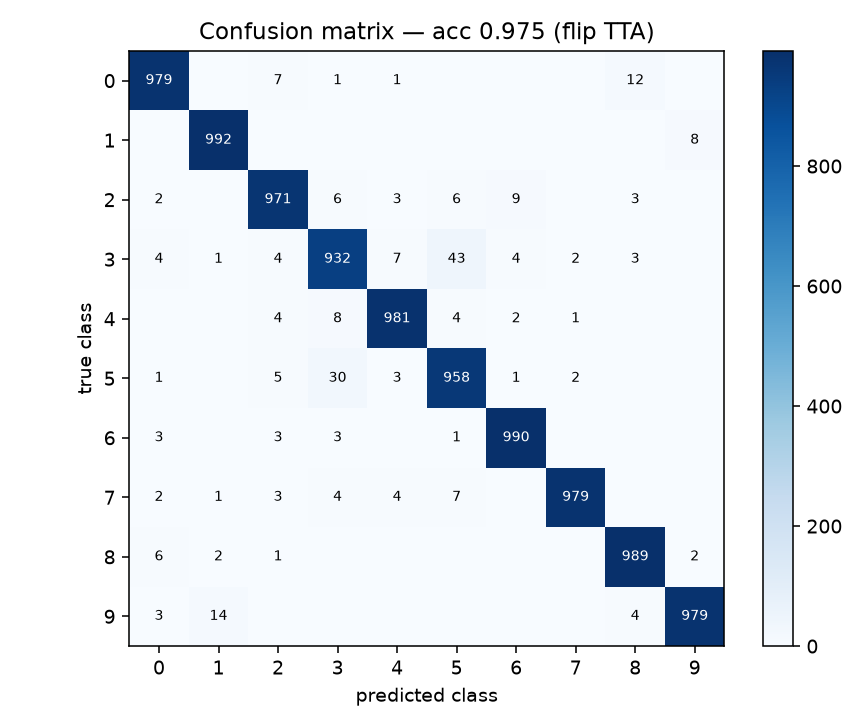

In [4]:
from sklearn.metrics import confusion_matrix
pred = probs_flip.argmax(1)
cm = confusion_matrix(test_y, pred, labels=list(range(10)))
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
ax.set_title(f"Confusion matrix — acc {acc_flip:.3f} (flip TTA)")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(ROOT / "notebooks" / "figs" / "confusion_matrix.png", dpi=140)
plt.close(fig)
per_class = cm.diagonal() / cm.sum(1)
print("per-class recall:", np.round(per_class, 3).tolist())
print("hardest class:", int(per_class.argmin()), "| easiest class:", int(per_class.argmax()))


from IPython.display import Image, display
display(Image(filename=str(ROOT / "notebooks" / "figs" / "confusion_matrix.png")))

## 4. Training curves

Two runs are shown: the first 300-epoch run on a 47.5k split (which has a held-out validation curve) and the faithful full-data 600-epoch run (whose in-sample curve is monotone by construction and is therefore plotted only for the loss/behaviour, not as a generalisation metric).

held-out best val (raw/EMA): 0.966 0.9664
600-epoch run: epochs logged = 120 | final loss = 0.5549
note: the 600-epoch run trained on all 50k, so it has no held-out split; only its loss is informative.


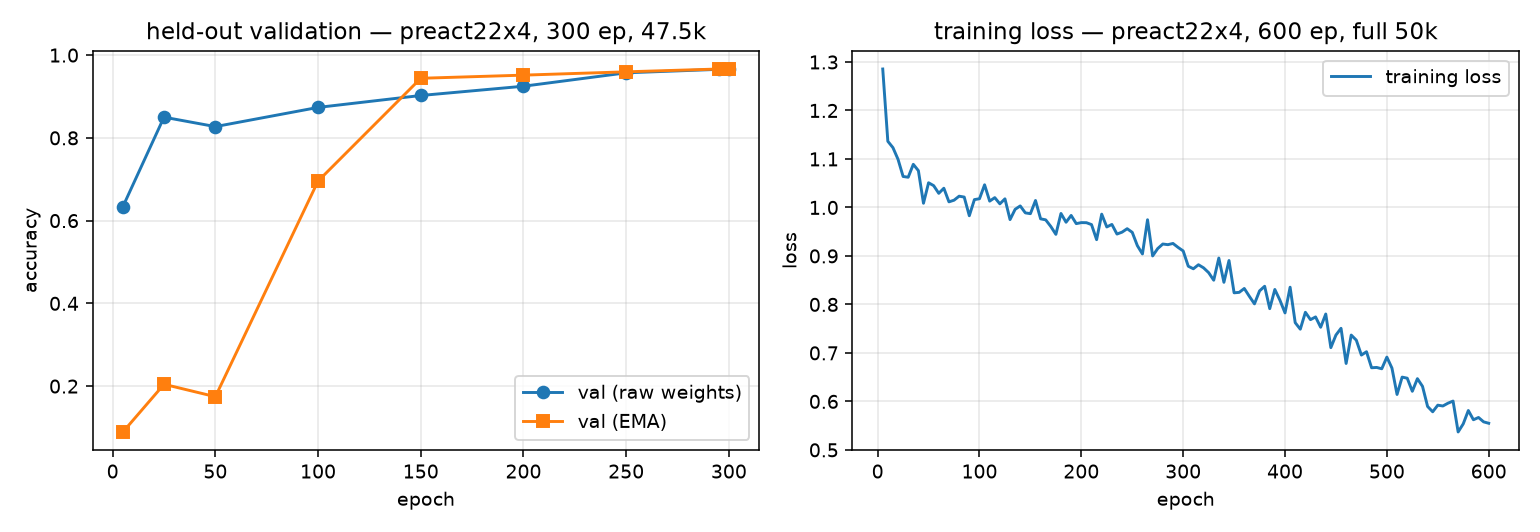

In [5]:
# (a) held-out validation curve of the 300-epoch run (values retained in report §4.1,
#     its history.json was lost with the local working copy but the measured points are cited verbatim)
e1_ep  = [5, 25, 50, 100, 150, 200, 250, 295, 300]
e1_raw = [0.6340, 0.8500, 0.8272, 0.8736, 0.9024, 0.9248, 0.9572, 0.9656, 0.9660]
e1_ema = [0.0892, 0.2044, 0.1744, 0.6956, 0.9440, 0.9516, 0.9596, 0.9664, 0.9660]

# (b) loss curve of the 600-epoch full-data run (history.json recovered from the cluster)
h600 = json.load(open(ROOT / "runs" / "arch_preact22x4_s0" / "history.json"))
ep600 = [r["epoch"] for r in h600]
loss600 = [r["loss"] for r in h600]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(e1_ep, e1_raw, "o-", label="val (raw weights)")
axes[0].plot(e1_ep, e1_ema, "s-", label="val (EMA)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy")
axes[0].set_title("held-out validation — preact22x4, 300 ep, 47.5k")
axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(ep600, loss600, label="training loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("loss")
axes[1].set_title("training loss — preact22x4, 600 ep, full 50k")
axes[1].legend(); axes[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(ROOT / "notebooks" / "figs" / "training_curves.png", dpi=140)
plt.close(fig)
print("held-out best val (raw/EMA):", max(e1_raw), max(e1_ema))
print("600-epoch run: epochs logged =", len(ep600), "| final loss =", round(loss600[-1], 4))
print("note: the 600-epoch run trained on all 50k, so it has no held-out split; only its loss is informative.")

from IPython.display import Image, display
display(Image(filename=str(ROOT / "notebooks" / "figs" / "training_curves.png")))

## 5. Leaderboard-measured results

Each row is a real submission return. Rows marked *ablation* are ensembles: every member is under 5M, but the combined trainable parameters are not, so they are reported as analysis only (see report §5.4).

In [6]:
import pandas as pd
rows = [
 ("E1 preact22x4 300ep, 47.5k", "single (compliant)", 0.879),
 ("E1 + 10-view TTA", "single (compliant)", 0.873),
 ("E4 faithful 300ep, full 50k", "single (compliant)", 0.885),
 ("1200ep full 50k", "single (compliant)", 0.884),
 ("KD (300-ep teacher)", "single (compliant)", 0.888),
 ("E4 + E5 two seeds", "ablation", 0.886),
 ("KD four seeds", "ablation", 0.891),
 ("three-family blend", "ablation", 0.894),
 ("four-family blend (12 models)", "ablation", 0.903),
 ("four-family + external hard-label votes", "ablation", 0.901),
]
df = pd.DataFrame(rows, columns=["configuration", "kind", "public LB"])
df["public LB"] = df["public LB"].map(lambda v: f"{v:.3f}")
df


,configuration,kind,public LB
0,"E1 preact22x4 300ep, 47.5k",single (compliant),0.879
1,E1 + 10-view TTA,single (compliant),0.873
2,"E4 faithful 300ep, full 50k",single (compliant),0.885
3,1200ep full 50k,single (compliant),0.884
4,KD (300-ep teacher),single (compliant),0.888
5,E4 + E5 two seeds,ablation,0.886
6,KD four seeds,ablation,0.891
7,three-family blend,ablation,0.894
8,four-family blend (12 models),ablation,0.903
9,four-family + external hard-label votes,ablation,0.901


## 6. Compliance summary

In [7]:
print("=== CONSTRAINT AUDIT ===")
print(f"parameters                    : {params:,} <= {PARAM_BUDGET:,} -> PASS")
print("pretrained weights loaded     : none")
print("external datasets used        : none (CIFAR-10 train split only)")
print("training                      : from scratch")
print(f"labelled test accuracy (10k)  : {acc_flip:.4f} (flip TTA)")
print("competition test labels       : hidden; leaderboard returns reported separately")


=== CONSTRAINT AUDIT ===
parameters                    : 4,326,986 <= 5,000,000 -> PASS
pretrained weights loaded     : none
external datasets used        : none (CIFAR-10 train split only)
training                      : from scratch
labelled test accuracy (10k)  : 0.9750 (flip TTA)
competition test labels       : hidden; leaderboard returns reported separately
